# Predicting Online Purchases
### DSA211 Regression and Classification · Group analysis

**Research question.** How accurately can browsing-session characteristics distinguish purchases (`Revenue=1`) from non-purchases, and which of the course-based classification models has the highest mean five-fold ROC-AUC?

This is a **prediction** project, not a causal study. The repository README contains the one-page workflow diagram.


## 0. Evaluation protocol

**Dataset and split.** We use 12,330 UCI browsing sessions, split into 9,864 training observations (80%) and 2,466 reserved observations (20%) using stratification and seed 42. EDA and model selection use training data.

**Candidate comparison.** First compare all 17 source predictors as an initial diagnostic. The subsequent models use 16 predictors because `PageValues` may not be available at the proposed prediction time. All candidate models share five stratified training folds, with preprocessing and any inner tuning fitted within training folds.

**Selection criterion.** Rank candidates by mean five-fold ROC-AUC, using average precision (AP) and fold variation as supporting metrics. For a within-family modification, require the improvement over its stated parent to exceed the candidate's own AUC standard error. This is a **selection heuristic**, not a significance test.

**Limitations.** The reserved set was examined during earlier analysis, so its reported score is **not a pristine independent holdout result**. ROC-AUC does not establish calibrated probabilities, causal effects or deployment-ready profit.


In [ ]:
from pathlib import Path
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, roc_curve, confusion_matrix

SEED=42; TEST_FRAC=.20; K=5; TARGET='Revenue'
NUMERIC_ALL=['Administrative','Administrative_Duration','Informational','Informational_Duration',
 'ProductRelated','ProductRelated_Duration','BounceRates','ExitRates','PageValues','SpecialDay']
CAT=['Month','OperatingSystems','Browser','Region','TrafficType','VisitorType']
ACTIVITY=['Administrative','Administrative_Duration','Informational','Informational_Duration','ProductRelated','ProductRelated_Duration']
NUMERIC_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']
ALL=NUMERIC_ALL+CAT+['Weekend']
SAFE=NUMERIC_SAFE+CAT+['Weekend']
EXPECTED=set(ALL+[TARGET])
data_path=next((p for p in [Path('data/online_shoppers.csv'),Path('../data/online_shoppers.csv')] if p.is_file()),None)
if data_path is None: raise FileNotFoundError('Expected data/online_shoppers.csv in the repository.')
print('Primary metric: mean five-fold ROC-AUC; supporting metric: average precision.')


## 1. Data quality and split

**Purpose.** Verify source completeness and establish training/holdout membership.

**Method.** Check missingness, outcome balance and duplicates; preserve all 12,330 sessions. Use training rows only for EDA, candidate selection and threshold comparisons.


In [ ]:
raw=pd.read_csv(data_path)
if len(raw)!=12330 or set(raw.columns)!=EXPECTED:
    raise ValueError('Unexpected dataset shape or columns.')
raw.insert(0,'_row_id',np.arange(len(raw),dtype=int))
missing=raw.drop(columns='_row_id').isna().sum()
print('Source shape:',(len(raw),len(raw.columns)-1))
print('Missing values:',int(missing.sum()))
print('Excess duplicated rows:',int(raw.duplicated(subset=raw.columns.drop('_row_id')).sum()))
display(raw[TARGET].value_counts().sort_index().rename_axis(TARGET).to_frame('sessions').assign(share=lambda d:d.sessions/len(raw)))

train_ids,test_ids=train_test_split(raw['_row_id'].to_numpy(),test_size=TEST_FRAC,
    stratify=raw[TARGET].to_numpy(),random_state=SEED)
train_ids=np.sort(train_ids);test_ids=np.sort(test_ids)
train=raw.set_index('_row_id').loc[train_ids].copy()
y_train=train.pop(TARGET).astype(int)
X_train=train[ALL].copy()
X_train[CAT]=X_train[CAT].astype('string')
X_train['Weekend']=X_train['Weekend'].astype(int)
del raw,train
cv=StratifiedKFold(n_splits=K,shuffle=True,random_state=SEED)
FOLD_INDICES=list(cv.split(np.zeros(len(y_train)),y_train))
print(f'Training={len(X_train):,}; reserved={len(test_ids):,}; training purchase share={y_train.mean():.2%}.')
print('Accuracy alone can be misleading when the target is imbalanced; duplicated sessions are retained as recorded.')


## 2. Numerical EDA

**Purpose.** Identify skew and excess zeros.

**Method.** Display median, zero share and skewness, with representative histograms.

**Implication.** Test log1p for long tails and fold-fitted presence indicators for zero-heavy activity.


,median,zero share,skew
Administrative,1.000,0.467,1.967
Administrative_Duration,8.000,0.477,5.679
Informational,0.000,0.785,4.142
Informational_Duration,0.000,0.805,7.702
ProductRelated,18.000,0.003,4.372
ProductRelated_Duration,600.537,0.062,8.009
BounceRates,0.003,0.448,2.924
ExitRates,0.025,0.006,2.130
PageValues,0.000,0.778,6.187
SpecialDay,0.000,0.897,3.261


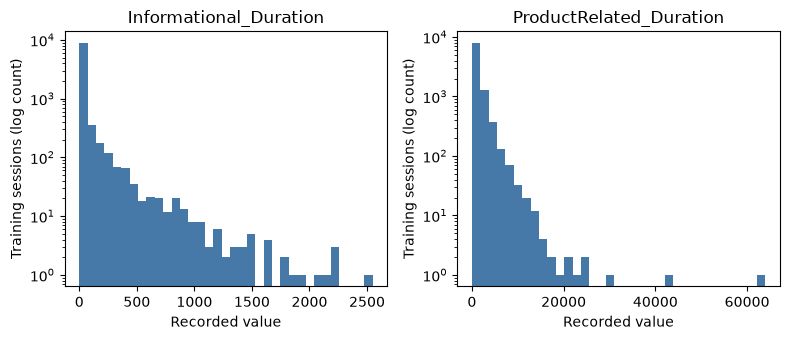

Interpretation: Informational has 78.5% zeros, Informational_Duration 80.5% zeros, and ProductRelated_Duration skew=8.01. These motivate, but do not validate, presence and log1p trials.


In [3]:
Xtr=X_train; ytr=y_train
num_summary=pd.DataFrame({'median':Xtr[NUMERIC_ALL].median(),'zero share':Xtr[NUMERIC_ALL].eq(0).mean(),
                          'skew':Xtr[NUMERIC_ALL].skew(),'buyer median':Xtr.loc[ytr.eq(1),NUMERIC_ALL].median(),
                          'nonbuyer median':Xtr.loc[ytr.eq(0),NUMERIC_ALL].median()})
display(num_summary[['median','zero share','skew']].round(3))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes.flat,['Informational_Duration','ProductRelated_Duration']):
    ax.hist(Xtr[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Training sessions (log count)')
plt.tight_layout(); plt.show()
long_tail=num_summary.loc[ACTIVITY,'skew']

print(f'Interpretation: Informational has {num_summary.loc["Informational","zero share"]:.1%} zeros, Informational_Duration {num_summary.loc["Informational_Duration","zero share"]:.1%} zeros, and ProductRelated_Duration skew={num_summary.loc["ProductRelated_Duration","skew"]:.2f}. These motivate, but do not validate, presence and log1p trials.')


### 2.1 Zero-versus-positive activity and positive intensity

The zero/positive comparison and positive-value quantile bins below informed the presence-indicator and log/intensity experiments. The purchase rates are **unadjusted training EDA**, not proof that presence causes purchasing or improves multivariable prediction.

In [ ]:
X=Xtr; y=ytr; NUMERIC=NUMERIC_ALL
rows=[]; details=[]
for col in ACTIVITY:
    pos=X[col]>0; rows.append({'feature':col,'skew':X[col].skew(),'zero_share':(~pos).mean(),'zero_n':(~pos).sum(),'zero_buyer_rate':y[~pos].mean(),'positive_n':pos.sum(),'positive_buyer_rate':y[pos].mean()})
    vals=X.loc[pos,col]
    for q,v in vals.quantile([.25,.5,.75,.9]).items(): details.append({'feature':col,'evidence':'positive quantile','level':q,'value':v})
    bins=pd.qcut(vals,4,duplicates='drop')
    t=pd.DataFrame({'bin':bins,'x':vals,'buyer':y[pos]}).groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyer_rate=('buyer','mean'))
    for b,r in t.iterrows(): details.append({'feature':col,'evidence':'positive intensity bin','level':str(b),'n':int(r.n),'value':r.mean_x,'buyer_rate':r.buyer_rate})
ACTIVITY_SUMMARY=pd.DataFrame(rows).set_index('feature'); display(ACTIVITY_SUMMARY.round(4)); display(pd.DataFrame(details).round(4))
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration']:
    r=ACTIVITY_SUMMARY.loc[col]
    print(f"{col}: skew={r['skew']:.2f}, zero={r['zero_share']:.1%}; buyer rate is {r['zero_buyer_rate']:.1%} at zero and {r['positive_buyer_rate']:.1%} above zero.")
eligible=ACTIVITY_SUMMARY[(ACTIVITY_SUMMARY['skew'].abs()>2)&(ACTIVITY_SUMMARY['zero_share']>=.50)].index.tolist()
print('Under the predeclared training EDA rule (|skew|>2 and zero share >=50%), candidate activity columns for fold-fitted presence indicators:', eligible or 'none')
print('Positive-only bins are broadly increasing for Informational and ProductRelated_Duration, but Administrative_Duration is uneven; bins are descriptive and do not establish conditional effects.')


## 3. Categorical EDA

**Purpose.** Compare observed buying rates across nominal levels.

**Method.** Summarise sparsity and show Month/VisitorType rates on training rows.

**Implication.** Encode nominal levels in each CV fit; avoid over-interpreting small groups.


In [4]:
cat_summary=[]
for col in CAT:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    cat_summary.append({'feature':col,'levels':len(tab),'small levels <50':int((tab.sessions<50).sum()),
      'small-level sessions':int(tab.loc[tab.sessions<50,'sessions'].sum()),
      'buyer-rate range':f"{tab.buyer_rate.min():.1%}–{tab.buyer_rate.max():.1%}"})
display(pd.DataFrame(cat_summary).set_index('feature')[['levels','small levels <50','buyer-rate range']])
for col in ['Month','VisitorType']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).sort_values('sessions',ascending=False)
    print(f'Training group counts and observed buyer rates: {col}')
    display(tab[['sessions','buyer_rate']].round(3))
rare=[]
for col in ['TrafficType','Browser','Region']:
    tab=Xtr.assign(Revenue=ytr).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))
    small=tab[tab.sessions<50]
    rare.append({'feature':col,'levels below n=50':len(small),'total levels':len(tab),
                 'rare-cell rate range':f"{small.buyer_rate.min():.1%}–{small.buyer_rate.max():.1%}" if len(small) else 'none'})
vtm=Xtr.assign(Revenue=ytr).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean')).reset_index()
special=Xtr.assign(Revenue=ytr).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),buyer_rate=('Revenue','mean'))

print(f'Interpretation: {int((Xtr.Browser.value_counts()<50).sum())} Browser and {int((Xtr.TrafficType.value_counts()<50).sum())} TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.')


,levels,small levels <50,buyer-rate range
feature,,,
Month,10,0,1.4%–24.8%
OperatingSystems,8,3,10.6%–25.0%
Browser,13,4,0.0%–42.9%
Region,9,0,14.2%–17.0%
TrafficType,20,9,0.0%–33.3%
VisitorType,3,0,14.0%–24.7%


Training group counts and observed buyer rates: Month


,sessions,buyer_rate
Month,,
May,2703,0.108
Nov,2360,0.248
Mar,1538,0.103
Dec,1391,0.132
Oct,444,0.221
Sep,368,0.204
Jul,344,0.134
Aug,342,0.178
June,228,0.101


Training group counts and observed buyer rates: VisitorType


,sessions,buyer_rate
VisitorType,,
Returning_Visitor,8443,0.140
New_Visitor,1347,0.247
Other,74,0.176


Interpretation: 4 Browser and 9 TrafficType levels have fewer than 50 training rows. Fold-fitted pooling is a hypothesis, not a guaranteed gain; all six categories remain nominal.


### 3.1 VisitorType × Month purchase rates and support

Use the session counts and rates together: four observed month-by-visitor cells have fewer than 50 sessions. This was used to avoid an unsupported VisitorType × Month interaction despite visible marginal variation.

In [ ]:
cross=X.assign(Revenue=y).groupby(['VisitorType','Month'],observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index()
display(cross.pivot(index='VisitorType',columns='Month',values='sessions').fillna(0).astype(int)); display(cross.pivot(index='VisitorType',columns='Month',values='purchase_rate').round(3))
fig,ax=plt.subplots(figsize=(9,3.8))
month_order=['Feb','Mar','May','June','Jul','Aug','Sep','Oct','Nov','Dec']
for v,g in cross.groupby('VisitorType'):
    g=g.assign(Month=pd.Categorical(g.Month,categories=month_order,ordered=True)).sort_values('Month')
    ax.plot(g.Month.astype(str),g.purchase_rate,marker='o',label=v)
ax.set(title='Training purchase rate by VisitorType and Month',xlabel='Month',ylabel='Observed purchase rate'); ax.legend(frameon=False,ncol=3); plt.tight_layout(); plt.show()
small=cross[cross.sessions<50].sort_values('sessions'); print('Cells below 50 sessions:',len(small)); display(small.round(3))
supported=cross[cross.sessions>=50].groupby('VisitorType').purchase_rate.agg(['min','max','count'])
print('Across supported months (n>=50), purchase-rate ranges by visitor type:')
display(supported.round(3))
for visitor,r in supported.iterrows(): print(f"{visitor}: supported-month purchase rates span {r['min']:.1%}–{r['max']:.1%} across {int(r['count'])} months.")
print('The observed month variation is descriptive and 4 cells are sparse; do not add a VisitorType × Month recipe from this evidence alone.')


### 3.2 Rare category levels

The full observed TrafficType, Browser and Region level counts are shown below. Thirteen of 42 levels have fewer than 50 sessions, which motivates cautious encoding and demonstrates why extreme small-cell rates are unreliable.

In [ ]:
rr=[]
for col in ['TrafficType','Browser','Region']:
    t=X.assign(Revenue=y).groupby(col,observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean'))
    for level,r in t.iterrows(): rr.append({'feature':col,'level':str(level),'sessions':int(r.sessions),'buyers':int(r.buyers),'purchase_rate':r.purchase_rate,'support':'<50' if r.sessions<50 else '>=50'})
RARE_LEVELS=pd.DataFrame(rr).sort_values(['feature','sessions','level']); display(RARE_LEVELS.round(4))
sparse=RARE_LEVELS[RARE_LEVELS.support=='<50']
print(f"{len(sparse)} of {len(RARE_LEVELS)} levels have <50 sessions. Among these, observed rates range {sparse.purchase_rate.min():.1%}–{sparse.purchase_rate.max():.1%}; examples at the extremes are highly uncertain. Keep levels nominal; this evidence does not justify arbitrary pooling.")


### 3.3 SpecialDay score versus positive presence

The numerical score is zero in 89.7% of training rows. These exact-score and zero-versus-positive rates suggests a possible binary encoding, although the displayed comparisons are not among the final seven displayed per family.


In [ ]:
sp=X.assign(Revenue=y).groupby('SpecialDay',observed=True).agg(sessions=('Revenue','size'),buyers=('Revenue','sum'),purchase_rate=('Revenue','mean')).reset_index().sort_values('SpecialDay'); display(sp.round(4))
pos=X.SpecialDay>0; special_binary=pd.DataFrame([{'group':'zero','sessions':(~pos).sum(),'buyers':y[~pos].sum(),'rate':y[~pos].mean()},{'group':'positive','sessions':pos.sum(),'buyers':y[pos].sum(),'rate':y[pos].mean()}]); display(special_binary.round(4))
fig,ax=plt.subplots(figsize=(6.5,3.2)); ax.plot(sp.SpecialDay,sp.purchase_rate,marker='o')
for r in sp.itertuples(): ax.annotate(f'n={r.sessions}',(r.SpecialDay,r.purchase_rate),xytext=(3,4),textcoords='offset points',fontsize=8)
ax.set(title='Training purchase rate by SpecialDay score',xlabel='Recorded score',ylabel='Observed purchase rate'); plt.tight_layout(); plt.show()
print(f"The zero/positive rates are {special_binary.loc[0,'rate']:.1%} and {special_binary.loc[1,'rate']:.1%}; positive-score values are not monotone in rate across their supports. This supports considering presence as a simple representation for the NB revision review, while retaining the numeric baseline.")


## 4. Predictor relationships and assumptions

**Purpose.** Assess dependence and departure from Gaussian shapes.

**Method.** Check selected within-class correlations and Q–Q plots.

**Implication.** Diagnostics motivate candidates; CV, not visual assumptions alone, evaluates performance.


BounceRates/ExitRates correlations are 0.915 for nonbuyers and 0.723 for buyers; ProductRelated/ProductRelated_Duration are 0.839 and 0.896. These selected differences do not establish unequal full covariance matrices.


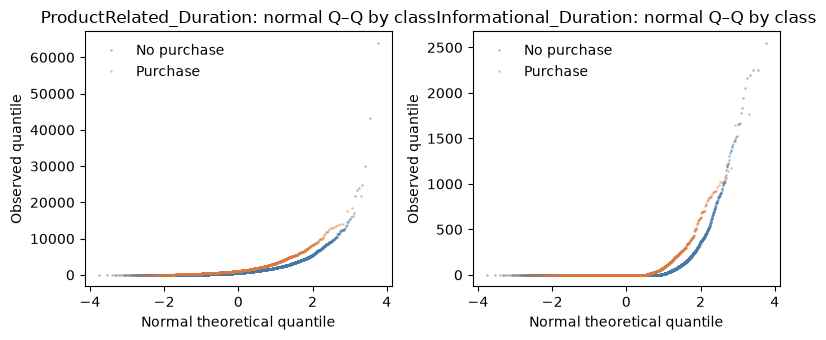

In [5]:
NUM_SAFE=[c for c in NUMERIC_ALL if c!='PageValues']+['Weekend']
for cls in [0,1]:
    corr=Xtr.loc[ytr.eq(cls),NUM_SAFE].corr().abs()
    pairs=corr.where(np.triu(np.ones(corr.shape),k=1).astype(bool)).stack().sort_values(ascending=False).head(5)
print('BounceRates/ExitRates correlations are {:.3f} for nonbuyers and {:.3f} for buyers; ProductRelated/ProductRelated_Duration are {:.3f} and {:.3f}. These selected differences do not establish unequal full covariance matrices.'.format(
 Xtr.loc[ytr.eq(0),['BounceRates','ExitRates']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['BounceRates','ExitRates']].corr().iloc[0,1],
 Xtr.loc[ytr.eq(0),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1],Xtr.loc[ytr.eq(1),['ProductRelated','ProductRelated_Duration']].corr().iloc[0,1]))
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
for ax,col in zip(axes,['ProductRelated_Duration','Informational_Duration']):
    for cls,label,color in [(0,'No purchase','#4779a8'),(1,'Purchase','#d97941')]:
        vals=Xtr.loc[ytr.eq(cls),col].to_numpy()
        (osm,osr),_=stats.probplot(vals,dist='norm',fit=True)
        ax.plot(osm,osr,'.',ms=2,alpha=.35,label=label,color=color)
    ax.set(title=f'{col}: normal Q–Q by class',xlabel='Normal theoretical quantile',ylabel='Observed quantile'); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

def marginal_elogit(col, bins=8):
    z=pd.DataFrame({'x':Xtr[col],'buyer':ytr}); z['bin']='zero'; positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],bins,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5))
    return out.sort_values('mean_x')


### 4.1 Predictor availability at the proposed intervention time

The original dataset does not include timestamps proving when each session metric becomes known. This training-source assessment supports excluding `PageValues` as a **timing precaution**, not as a demonstrated instance of leakage; other inputs also require a deployment-time audit.

In [ ]:
timing=[
('Administrative','Session count of administrative pages','Accumulator may evolve until session end','Unverified'),('Administrative_Duration','Time on administrative pages','Accumulator may evolve until session end','Unverified'),('Informational','Session count of informational pages','Accumulator may evolve until session end','Unverified'),('Informational_Duration','Time on informational pages','Accumulator may evolve until session end','Unverified'),('ProductRelated','Session count of product pages','Accumulator may evolve until session end','Unverified'),('ProductRelated_Duration','Time on product pages','Accumulator may evolve until session end','Unverified'),('BounceRates','Analytics bounce measure','May depend on session completion/processing','Timing unknown'),('ExitRates','Analytics exit measure','May depend on page exit/session completion','Timing unknown'),('PageValues','Analytics page value related to transaction likelihood/value','Could reflect completed-session information','Possible downstream timing; exclude operationally'),('SpecialDay','Calendar proximity score','Calendar-derived','Likely known; unverified'),('Month','Visit month','Calendar-derived','Likely known; unverified'),('OperatingSystems','Operating system category','Potentially observed at arrival','Likely early; unverified'),('Browser','Browser category','Potentially observed at arrival','Likely early; unverified'),('Region','Visitor region category','Geolocation/analytics processing may vary','Unverified'),('TrafficType','Traffic source category','Attribution timing may vary','Unverified'),('VisitorType','New/returning visitor category','May rely on cookies/prior-visit linkage','Unverified'),('Weekend','Weekend indicator','Calendar-derived','Likely known; unverified')]
AVAILABILITY=pd.DataFrame(timing,columns=['predictor','measure','possible timing issue','assessment']); display(AVAILABILITY)
print('PageValues has the clearest possible downstream timing concern; remaining features also require a real decision-time audit.')


### 4.2 Distribution tails, class correlations and binned empirical logits

This complete training-only diagnostic checks marginal skew, zero mass, p95, class-specific correlations and observed purchase patterns across predictor bins. It informed the log transformations, positive-presence trials, nonlinear BounceRates hypothesis and dependence-aware Gaussian NB/LDA tests. A marginal empirical logit is **not** a fitted multivariable logistic coefficient.

In [ ]:
allnum=NUMERIC+['Weekend']; shape=pd.DataFrame({'skew':X[allnum].skew(),'zero_share':X[allnum].eq(0).mean(),'median':X[allnum].median(),'p95':X[allnum].quantile(.95)})
display(shape.round(4))
for cls in [0,1]:
    cor=X.loc[y==cls,allnum].corr().abs(); pairs=cor.where(np.triu(np.ones(cor.shape),1).astype(bool)).stack().sort_values(ascending=False).head(6); display(pairs.rename(f'class {cls} absolute correlation').to_frame())
def elogit(col):
    z=pd.DataFrame({'x':X[col],'buyer':y}); z['bin']='zero'
    positive=z.x.gt(0)
    if positive.any(): z.loc[positive,'bin']=pd.qcut(z.loc[positive,'x'],8,duplicates='drop').astype(str)
    out=z.groupby('bin',observed=True).agg(n=('buyer','size'),mean_x=('x','mean'),buyers=('buyer','sum'),rate=('buyer','mean')).reset_index()
    out['bin']=out['bin'].astype(str)
    out['empirical_logit']=np.log((out.buyers+.5)/(out.n-out.buyers+.5)); return out.sort_values('mean_x')
for col in ['Informational','Informational_Duration','Administrative','Administrative_Duration','ProductRelated_Duration','BounceRates']:
    print('Binned marginal empirical logit, zero retained as one stratum:',col); display(elogit(col).round(4))
fig,axs=plt.subplots(2,2,figsize=(9,6))
for ax,col in zip(axs.flat,['Informational_Duration','Administrative_Duration','ProductRelated_Duration','BounceRates']):
    ax.hist(X[col],bins=35,log=True,color='#4779a8'); ax.set(title=col,xlabel='Recorded value',ylabel='Sessions (log scale)')
plt.tight_layout(); plt.show()
activity=shape.loc[ACTIVITY]
print('Activity fields with |skew|>2:',activity.index[activity['skew'].abs()>2].tolist())
print('Activity fields with training zero share >=50%:',activity.index[activity['zero_share']>=.50].tolist())
print('The training evidence shows long right tails across five of six activity fields and high zero prevalence for both informational measures; this supports evaluating the plan’s fixed log1p form and fold-fitted indicators for those high-zero fields. Strong within-class dependence (notably BounceRates/ExitRates and ProductRelated/ProductRelated_Duration) challenges Naive Bayes conditional independence. The observed class-specific correlation differences suggest possible covariance heterogeneity, but these selected pairs do not establish unequal full covariance matrices. Long tails and mixed numeric/nominal inputs challenge LDA’s multivariate Gaussian ideal; correlated predictors alone do not violate LDA’s covariance assumption. No model has been fitted or compared.')


### EDA-to-experiment bridge

The following are **training-only descriptive observations**, not proof that a proposed transformation will improve future accuracy.

| Training EDA observation | Modelling hypotheses represented below |
|---|---|
| ProductRelated_Duration skew **8.01**, Informational_Duration skew **7.70**, Administrative_Duration skew **5.68** | L1, D1 and G1 test `log1p`; G7 and G8 test targeted marginal transformations; D9 tests winsorisation |
| Informational has **78.5% zeros**, Informational_Duration **80.5% zeros** | D10 tests positive-presence; L1 and other transforms account for zero-heavy engagement |
| BounceRates has **44.8% zeros** and skew **2.92** | L8 tests piecewise behaviour; D11 tests zero/low/high binning |
| Within-class BounceRates–ExitRates correlation **0.915** for nonbuyers and **0.723** for buyers | L4/L13/L14 test shrinkage; G2 and B4 test dropping a dependent input |
| Within-class ProductRelated–ProductRelated_Duration correlation **0.839** for nonbuyers and **0.896** for buyers | G3/G6 directly compare deleting different correlated inputs; D15 tests grouped feature elimination |
| Four Browser and nine TrafficType levels have fewer than 50 training observations | Fold-safe one-hot encoding and cautious interpretation; sparse categories are **not** an independent reason to claim improved AUC |

**Caution:** Marginal skewness does not establish multivariate Gaussianity; correlated predictors challenge Naive Bayes' conditional independence assumption. The original one-SE CV acceptance rule, not an EDA impression, determines which stated modification was retained.

**Complete supporting EDA** from the training data appears directly above: zero-versus-positive rates, activity intensity, VisitorType×Month support, rare nominal levels, SpecialDay patterns, decision-time feature availability, tails, within-class correlations and marginal empirical logits. Sections 7.1–7.4 refer to this evidence, not just numerical skewness alone.


In [ ]:
# Fold-safe feature transformations and the classifiers used below.
C_GRID=[0.05,0.2,1.0,5.0,20.0]
REG_C_GRID=[0.01,0.05,0.2,1.0,5.0,20.0]
SHRINKAGE_GRID=[0.0,0.1,0.3,0.6,0.9]
RARE_MIN_COUNT=50
INNER_FOLDS=3
FAMILY_ORDER=['Logit','LDA','GaussianNB','BernoulliNB']
class FoldSafeFeatures(BaseEstimator, TransformerMixin):
    """Train-fold-only feature engineering. Categorical levels are never treated as ordinal."""
    def __init__(self, family='Logit', columns=(), log_activity=False,
                 presence=False, rare_pool=False, special_binary=False,
                 drop_features=(), median_cols=(), scale=False,
                 presence_cols=(), log_cols=(), quadratic_cols=(),
                 special_categorical=False, drop_nominal=False,
                 bounce_piecewise=False, bounce_binned=False,
                 winsor_cols=(), avg_product_duration=False):
        self.family=family
        self.columns=columns
        self.log_activity=log_activity
        self.presence=presence
        self.rare_pool=rare_pool
        self.special_binary=special_binary
        self.drop_features=drop_features
        self.median_cols=median_cols
        self.scale=scale
        self.presence_cols=presence_cols
        self.log_cols=log_cols
        self.quadratic_cols=quadratic_cols
        self.special_categorical=special_categorical
        self.drop_nominal=drop_nominal
        self.bounce_piecewise=bounce_piecewise
        self.bounce_binned=bounce_binned
        self.winsor_cols=winsor_cols
        self.avg_product_duration=avg_product_duration

    def _blocks(self,X):
        active=[c for c in self.columns if c not in self.drop_features
                and not (self.drop_nominal and c in CAT)]
        cats=[c for c in CAT if c in active]
        if self.special_categorical and 'SpecialDay' in active:
            cats.append('SpecialDay')
        if self.bounce_binned and 'BounceRates' in active:
            cats.append('BounceRates')
        nums=[c for c in active if c not in cats]
        z=pd.DataFrame(index=X.index)
        for c in nums:
            value=X[c].astype(float)
            if c=='BounceRates' and self.bounce_piecewise:
                z['BounceRates__positive']=(value>0).astype(float)
                z['BounceRates__up_to_001']=np.minimum(value,0.01)
                z['BounceRates__above_001']=np.maximum(value-0.01,0.0)
                continue
            if c in self.winsor_cols:
                z[c]=value.clip(upper=self.winsor_cutoffs_[c])
                continue
            if self.family=='BernoulliNB':
                if c in self.median_cols:
                    z[c]=(value>self.medians_[c]).astype(float)
                elif c=='Weekend':
                    z[c]=value
                else:
                    z[c]=(value>0).astype(float)
            elif self.special_binary and c=='SpecialDay':
                z[c]=(value>0).astype(float)
            elif (self.log_activity and c in ACTIVITY) or c in self.log_cols:
                z[c]=np.log1p(value)
            else:
                z[c]=value
        if self.presence:
            for c in ('Informational','Informational_Duration'):
                if c in active:
                    z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.presence_cols:
            if c in active:
                z[c+'__positive']=(X[c].astype(float)>0).astype(float)
        for c in self.quadratic_cols:
            if c in active:
                z[c+'__squared']=X[c].astype(float)**2
        if self.avg_product_duration:
            # Zero page-count sessions receive 0, without dividing by zero.
            pages=X['ProductRelated'].astype(float).to_numpy()
            seconds=X['ProductRelated_Duration'].astype(float).to_numpy()
            z['ProductRelated__duration_per_page']=np.divide(
                seconds,pages,out=np.zeros_like(seconds,dtype=float),
                where=pages>0)
        cat=pd.DataFrame(index=X.index)
        for c in cats:
            if c=='BounceRates' and self.bounce_binned:
                b=X[c].astype(float)
                values=pd.Series(np.where(b.eq(0),'zero',
                    np.where(b.le(0.01),'low-positive','high-positive')),
                    index=X.index)
            else:
                values=X[c].astype(str)
            if self.rare_pool and c in ('Browser','TrafficType'):
                values=values.where(values.isin(self.major_levels_[c]),'__OTHER__')
            cat[c]=values
        return z,cat

    def fit(self,X,y=None):
        self.n_features_in_=X.shape[1]
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.major_levels_={}
        for c in ('Browser','TrafficType'):
            if c in X and self.rare_pool:
                counts=X[c].astype(str).value_counts()
                self.major_levels_[c]=set(counts.index[counts>=RARE_MIN_COUNT])
        self.medians_={c:float(X[c].median()) for c in self.median_cols}
        self.winsor_cutoffs_={c:float(X[c].quantile(0.99)) for c in self.winsor_cols}
        num,cat=self._blocks(X)
        self.numeric_names_=list(num.columns)
        self.categorical_names_=list(cat.columns)
        self.encoder_=OneHotEncoder(
            drop='first' if self.family in ('Logit','LDA') else None,
            handle_unknown='ignore',sparse_output=False
        )
        if self.categorical_names_:
            self.encoder_.fit(cat)
        transformed=self._encode(num,cat)
        if self.scale:
            self.scaler_=StandardScaler().fit(transformed)
        return self

    def _encode(self,num,cat):
        blocks=[num.to_numpy(dtype=float)]
        if self.categorical_names_:
            blocks.append(self.encoder_.transform(cat))
        Z=np.column_stack(blocks)
        if not np.isfinite(Z).all():
            raise ValueError('Non-finite preprocessing output')
        return Z

    def transform(self,X):
        num,cat=self._blocks(X)
        Z=self._encode(num,cat)
        return self.scaler_.transform(Z) if self.scale else Z

    def get_feature_names_out(self,input_features=None):
        names=list(self.numeric_names_)
        if self.categorical_names_:
            names+=list(self.encoder_.get_feature_names_out(self.categorical_names_))
        return np.asarray(names,dtype=object)


class BackwardSelectedLDA(BaseEstimator, ClassifierMixin):
    """Leakage-free grouped backward source selection inside each outer training fit.

    A fixed set of inner folds evaluates *every candidate removal* from the current
    subset, then chooses subset size by the course's simplest-within-1SE rule.
    Outer validation outcomes are never used in this search.
    """
    def __init__(self, columns=(), inner_folds=3, seed=42):
        self.columns=columns
        self.inner_folds=inner_folds
        self.seed=seed

    def fit(self,X,y):
        yv=np.asarray(y,dtype=int)
        cv=StratifiedKFold(n_splits=self.inner_folds,shuffle=True,random_state=self.seed)
        cached=[]
        for fit_idx,val_idx in cv.split(X,yv):
            pre=FoldSafeFeatures(family='LDA',columns=tuple(self.columns))
            zfit=pre.fit_transform(X.iloc[fit_idx])
            zval=pre.transform(X.iloc[val_idx])
            feat=list(pre.get_feature_names_out())
            groups={}
            for name in self.columns:
                if name in pre.numeric_names_:
                    groups[name]=[feat.index(name)]
                else:
                    groups[name]=[i for i,c in enumerate(feat) if c.startswith(name+'_')]
                if not groups[name]:
                    raise RuntimeError(f'No encoded columns for {name}')
            all_indices=[i for g in groups.values() for i in g]
            if len(all_indices)!=len(set(all_indices)) or sorted(all_indices)!=list(range(len(feat))):
                raise RuntimeError('Source-group index mapping is not a partition')
            cached.append((zfit,zval,yv[fit_idx],yv[val_idx],groups))

        def cross_validated_score(selected):
            fold_scores=[]
            for zfit,zval,yfit,yval,groups in cached:
                indices=sorted(i for name in selected for i in groups[name])
                clf=LinearDiscriminantAnalysis(solver='svd')
                clf.fit(zfit[:,indices],yfit)
                p=clf.predict_proba(zval[:,indices])[:,1]
                fold_scores.append(float(roc_auc_score(yval,p)))
            a=np.asarray(fold_scores,dtype=float)
            return float(a.mean()),float(a.std(ddof=1)/np.sqrt(len(a))),a.tolist()

        remaining=tuple(self.columns)
        self.selection_path_=[]
        prior=None
        while True:
            if prior is None:
                candidates=[remaining]
            else:
                candidates=[tuple(c for c in remaining if c!=drop) for drop in remaining]
            options=[]
            for option in candidates:
                avg,se,fold_scores=cross_validated_score(option)
                # Maximise AUC; stable tie by original order of the removed source.
                options.append((avg,se,fold_scores,option))
            options.sort(key=lambda x:(-x[0],tuple(self.columns.index(c) for c in x[3])))
            avg,se,fold_scores,chosen=options[0]
            self.selection_path_.append({'source_count':len(chosen),'selected_sources':list(chosen),
                        'inner_mean_auc':avg,'inner_auc_se':se,
                        'inner_fold_aucs':fold_scores})
            remaining=chosen
            prior=True
            if len(remaining)==1:
                break
        best=sorted(self.selection_path_,key=lambda v:(-v['inner_mean_auc'],-v['source_count']))[0]
        self.one_se_cutoff_=best['inner_mean_auc']-best['inner_auc_se']
        eligible=[p for p in self.selection_path_
                  if p['inner_mean_auc']>=self.one_se_cutoff_-1e-14]
        selected=sorted(eligible,key=lambda p:(p['source_count'],-p['inner_mean_auc']))[0]
        self.selected_source_cols_=tuple(selected['selected_sources'])
        self.selected_source_count_=len(self.selected_source_cols_)
        self.inner_selected_auc_=selected['inner_mean_auc']
        self.inner_best_size_=best['source_count']
        self.model_=Pipeline([
            ('pre',FoldSafeFeatures(family='LDA',columns=self.selected_source_cols_)),
            ('clf',LinearDiscriminantAnalysis(solver='svd'))
        ])
        self.model_.fit(X,y)
        self.named_steps=self.model_.named_steps
        self.classes_=self.model_.named_steps['clf'].classes_
        self.n_features_in_=X.shape[1]
        return self

    def predict_proba(self,X):
        return self.model_.predict_proba(X)

    def predict(self,X):
        return self.model_.predict(X)

def build_model(family,config=None,columns=SAFE):
    cfg=dict(config or {})
    tune=cfg.pop('tune',None)
    backward=bool(cfg.pop('backward_select',False))
    if backward:
        if family!='LDA' or tune is not None or cfg:
            raise ValueError('Backward source selection only supports D0 LDA')
        return BackwardSelectedLDA(columns=tuple(columns),inner_folds=INNER_FOLDS,seed=SEED)
    pre=FoldSafeFeatures(family=family,columns=tuple(columns),**cfg)
    if family=='Logit':
        if tune=='logit':
            clf=LogisticRegression(solver='lbfgs',max_iter=1600,tol=1e-6)
        elif tune=='lasso':
            clf=LogisticRegression(penalty='l1',solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune=='elasticnet':
            clf=LogisticRegression(penalty='elasticnet',l1_ratio=0.5,solver='saga',
                                    max_iter=10000,tol=1e-4,random_state=SEED)
        elif tune is None:
            clf=LogisticRegression(C=np.inf,solver='newton-cg',tol=1e-8,max_iter=2000)
        else:
            raise ValueError(f'Unknown Logit penalty: {tune}')
    elif family=='LDA':
        clf=LinearDiscriminantAnalysis(solver='lsqr' if tune=='lda' else 'svd')
    elif family=='GaussianNB':
        clf=GaussianNB()
    elif family=='BernoulliNB':
        clf=BernoulliNB(binarize=None)
    else:
        raise ValueError(family)
    pipe=Pipeline([('pre',pre),('clf',clf)])
    if tune:
        if tune in ('logit','lasso','elasticnet'):
            params={'clf__C':REG_C_GRID if tune in ('lasso','elasticnet') else C_GRID}
        elif tune=='lda':
            params={'clf__shrinkage':SHRINKAGE_GRID}
        else:
            raise ValueError(f'Unsupported tune: {tune}')
        inner=StratifiedKFold(n_splits=INNER_FOLDS,shuffle=True,random_state=SEED)
        return GridSearchCV(pipe,params,cv=inner,scoring='roc_auc',
                            n_jobs=1,refit=True,error_score='raise')
    return pipe

def run_spec(label,family,columns,pipeline_factory=None):
    oof=np.empty(len(ytr),dtype=float)
    folds=[]; warning_count=0
    for fold,(fit_idx,val_idx) in enumerate(FOLD_INDICES,1):
        fit_x=Xtr.iloc[fit_idx][columns]; val_x=Xtr.iloc[val_idx][columns]
        fit_y=ytr.iloc[fit_idx]; val_y=ytr.iloc[val_idx]
        model=pipeline_factory() if pipeline_factory else build_model(family,{},columns)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            model.fit(fit_x,fit_y)
            p=np.asarray(model.predict_proba(val_x)[:,1],dtype=float)
        warning_count+=len(caught)
        if not np.isfinite(p).all() or ((p<0)|(p>1)).any():
            raise ValueError(f'Invalid probabilities: {label}, fold {fold}')
        oof[val_idx]=p
        folds.append({'fold':fold,'roc_auc':float(roc_auc_score(val_y,p)),
                      'average_precision':float(average_precision_score(val_y,p))})
    auc=np.array([x['roc_auc'] for x in folds]);ap=np.array([x['average_precision'] for x in folds])
    return {'candidate':label,'family':family,'status':'SCORED',
            'folds':folds,'oof':oof,'warning_count':warning_count,
            'mean_fold_auc':float(auc.mean()),'fold_auc_sd':float(auc.std(ddof=1)),
            'fold_auc_se':float(auc.std(ddof=1)/np.sqrt(K)),
            'mean_fold_ap':float(ap.mean()),
            'pooled_oof_auc':float(roc_auc_score(ytr,oof)),
            'pooled_oof_ap':float(average_precision_score(ytr,oof))}

TREE_FAMILIES={'GiniTree':'gini','EntropyTree':'entropy'}
def tree_pipeline(family,alpha=0.,columns=SAFE):
    return Pipeline([('pre',FoldSafeFeatures(family=family,columns=tuple(columns))),
        ('clf',DecisionTreeClassifier(criterion=TREE_FAMILIES[family],
             ccp_alpha=float(alpha),max_depth=None,min_samples_leaf=1,
             min_samples_split=2,class_weight=None,random_state=SEED))])
RESULTS={}


## 5. Six all-17 first-pass models

**Purpose.** Compare four classifiers and two tree criteria using all 17 predictors as an initial diagnostic. These scores do not determine the final model.


In [ ]:
for f in [*FAMILY_ORDER,*TREE_FAMILIES]:
    label=f'All17 | {f}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,f,ALL,
        pipeline_factory=(lambda fam=f:tree_pipeline(fam,0.,ALL)) if f in TREE_FAMILIES else None)
ALL17=pd.DataFrame([{'candidate':f'All17 | {f}',
    'mean ROC-AUC':RESULTS[f'All17 | {f}']['mean_fold_auc'],
    'AUC SD':RESULTS[f'All17 | {f}']['fold_auc_sd'],
    'mean AP':RESULTS[f'All17 | {f}']['mean_fold_ap']}
    for f in [*FAMILY_ORDER,*TREE_FAMILIES]]).set_index('candidate')
display(ALL17.round(4))


**Interpretation.** `PageValues` may be unavailable when prediction would be required. Exclude it from operational models as a precaution; a strong association alone does not establish leakage.


In [8]:
# PageValues descriptive association on training rows only
pv=Xtr.assign(Revenue=ytr).groupby(Xtr.PageValues.gt(0).map({False:'PageValues = 0',True:'PageValues > 0'})).Revenue.agg(sessions='size',buyers='sum',buyer_rate='mean')
display(pv)
print('The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.')


,sessions,buyers,buyer_rate
PageValues,,,
PageValues = 0,7671,286,0.037283
PageValues > 0,2193,1240,0.565435


The above difference is descriptive. PageValues is excluded from operational predictors because its availability at the intended prediction time is uncertain, not because association proves leakage.


## 6. Six operational 16-variable baselines

**Purpose.** Compare the four classifier families and Gini/Entropy classification trees on the same 16 predictors, omitting `PageValues` as a timing precaution rather than proven leakage. These baselines are the starting points for EDA-guided model improvements.


In [ ]:
for f in [*FAMILY_ORDER,*TREE_FAMILIES]:
    label=f'Operational16 | {f}'
    print('Fitting',label,flush=True)
    RESULTS[label]=run_spec(label,f,SAFE,
        pipeline_factory=(lambda fam=f:tree_pipeline(fam,0.,SAFE)) if f in TREE_FAMILIES else None)
OP16=pd.DataFrame([{'candidate':f'Operational16 | {f}',
    'mean ROC-AUC':RESULTS[f'Operational16 | {f}']['mean_fold_auc'],
    'AUC SD':RESULTS[f'Operational16 | {f}']['fold_auc_sd'],
    'mean AP':RESULTS[f'Operational16 | {f}']['mean_fold_ap']}
    for f in [*FAMILY_ORDER,*TREE_FAMILIES]]).set_index('candidate')
display(OP16.round(4))
ALL17_VS_16=pd.DataFrame([{'family':f,
    'all17_mean_auc':RESULTS[f'All17 | {f}']['mean_fold_auc'],
    'operational16_mean_auc':RESULTS[f'Operational16 | {f}']['mean_fold_auc'],
    'all17_mean_ap':RESULTS[f'All17 | {f}']['mean_fold_ap'],
    'operational16_mean_ap':RESULTS[f'Operational16 | {f}']['mean_fold_ap']}
    for f in [*FAMILY_ORDER,*TREE_FAMILIES]])
display(ALL17_VS_16.round(5))
print('Excluding PageValues is a decision-time precaution, not evidence of confirmed leakage.')


## 7. EDA-guided model development — 26 compared specifications

Each classifier family begins with its 16-variable baseline. We evaluate the transformations and methods listed in that family's table. Below each table, the model IDs are explained with their motivation, parent comparison and retained/rejected decision.

**Decision rule:** retain a modification if the improvement in mean five-fold ROC-AUC over its stated comparison model strictly exceeds its own AUC standard error. If multiple independently tested modifications qualify, keep the qualifying candidate with the highest mean AUC. This is a model-selection heuristic, **not a statistical significance test**.


In [ ]:
# Model IDs match the tables and explanations immediately below.
SPECS={
 'Logit':[('L0',None,{}),('L1','L0',{'log_activity':True}),
   ('L4','L1',{'log_activity':True,'scale':True,'tune':'logit'}),
   ('L7','L1',{'log_activity':True,'presence_cols':('ProductRelated_Duration',)}),
   ('L8','L1',{'log_activity':True,'bounce_piecewise':True}),
   ('L13','L1',{'log_activity':True,'scale':True,'tune':'lasso'}),
   ('L14','L1',{'log_activity':True,'scale':True,'tune':'elasticnet'})],
 'LDA':[('D0',None,{}),('D1','D0',{'log_activity':True}),
   ('D4','D0',{'tune':'lda'}),
   ('D9','D0',{'winsor_cols':('ProductRelated_Duration',)}),
   ('D10','D0',{'presence_cols':('Informational',)}),
   ('D11','D0',{'bounce_binned':True}),
   ('D15','D0',{'backward_select':True})],
 'GaussianNB':[('G0',None,{}),('G1','G0',{'log_activity':True}),
   ('G2','G0',{'drop_features':('BounceRates',)}),
   ('G3','G0',{'drop_features':('ProductRelated',)}),
   ('G6','G0',{'drop_features':('ProductRelated_Duration',)}),
   ('G7','G0',{'log_cols':('ProductRelated_Duration',)}),
   ('G8','G0',{'log_cols':('Administrative_Duration',)})],
 'BernoulliNB':[('B0',None,{}),
   ('B1','B0',{'median_cols':('ProductRelated',)}),
   ('B2','B1',{'median_cols':('ProductRelated','ProductRelated_Duration')}),
   ('B3','B1',{'median_cols':('ProductRelated','ExitRates')}),
   ('B4','B3',{'median_cols':('ProductRelated','ExitRates'),
              'drop_features':('BounceRates',)})]
}
PATH_FINALISTS={}; PATH_FINAL_CONFIGS={}
def run_family(family):
    rows=[]; configs={}
    for code,parent,cfg in SPECS[family]:
        label=f'Operational16 | {family}' if parent is None else f'{code} | {family}'
        if parent is None: result=RESULTS[label]
        else:
            print('Testing',label,flush=True)
            result=run_spec(label,family,SAFE,
                pipeline_factory=lambda f=family,c=cfg:build_model(f,c,SAFE))
            RESULTS[label]=result
        configs[label]=cfg
        baseline=f'Operational16 | {family}'
        parent_label=(baseline if parent and parent.endswith('0') else
                      f'{parent} | {family}' if parent else None)
        gain=result['mean_fold_auc']-RESULTS[parent_label]['mean_fold_auc'] if parent else np.nan
        qualified=(gain>result['fold_auc_se']) if parent else True
        rows.append({'ID':code,'candidate':label,'CV ROC-AUC':result['mean_fold_auc'],
                     'AUC SE':result['fold_auc_se'],'CV AP':result['mean_fold_ap'],
                     'AUC gain':gain,'qualified':qualified})
    finalists=[r for r in rows if r['qualified']]
    selected=sorted(finalists,key=lambda r:(-r['CV ROC-AUC'],r['ID']))[0]
    PATH_FINALISTS[family]=selected['candidate']
    PATH_FINAL_CONFIGS[family]=configs[selected['candidate']]
    display(pd.DataFrame(rows)[['ID','CV ROC-AUC','AUC SE','CV AP','AUC gain']].round(5))
    print('Retained family model:',selected['ID'])


### 7.1 Logistic Regression — seven compared specifications

Baseline plus selected transformations, nonlinear specifications and Lecture 9 regularisation adaptations.


In [ ]:
run_family('Logit')


**Iteration-by-iteration decisions and EDA justification**

- **L0 (baseline):** Baseline using all 16 operational predictors.
- **L1:** Applied `log1p` to the six activity variables to address right-skew; **accepted and retained**. Tested against **Operational16 | Logit**.
- **L4:** Tested L2 (Ridge-style) penalisation with inner-CV tuning because several predictors are strongly correlated; **not accepted**. Tested against **L1 | Logit**.
- **L7:** Added a `ProductRelated_Duration > 0` indicator: purchase rates were **1.3%** for zero duration versus **16.4%** for positive duration; higher point AUC did not clear the fixed hurdle. Tested against **L1 | Logit**.
- **L8:** Tested piecewise `BounceRates` due to its zero mass and nonlinear-looking purchase rates; **not accepted**. Tested against **L1 | Logit**.
- **L13:** Tested LASSO-penalised logistic regression (Lecture 9 adaptation) for sparse coefficients and redundancy; **not accepted**. Tested against **L1 | Logit**.
- **L14:** Tested Elastic Net (Lecture 9 adaptation), combining L1/L2 shrinkage of correlated predictors; **not accepted**. Tested against **L1 | Logit**.

**Overall:** Only L1 qualified and survived. L7's higher point-estimate AUC was smaller than its own SE once compared against L1; the conservative selection rule did not select it.


### 7.2 Linear Discriminant Analysis — seven compared specifications

D0 is the **baseline**. Distributional transformations, covariance shrinkage and Lecture 8 backward selection are evaluated against it.


In [ ]:
run_family('LDA')


**Iteration-by-iteration decisions and EDA justification**

- **D0 (baseline):** **Baseline.** D0 stays the family finalist because no LDA modification met the selection rule.
- **D1:** Applied `log1p` to all six activity variables due to long tails and departures from normality; **not accepted**. Tested against **Operational16 | LDA**.
- **D4:** Tested inner-CV covariance shrinkage in response to within-class dependence; **not accepted**. Tested against **Operational16 | LDA**.
- **D9:** Winsorised `ProductRelated_Duration` at fold-training p99 to reduce tail sensitivity; **not accepted**. Tested against **Operational16 | LDA**.
- **D10:** Added `Informational > 0`: purchase rates were **13.3%** for zero versus **23.4%** for positive; **not accepted**. Tested against **Operational16 | LDA**.
- **D11:** Binned `BounceRates` into zero/low/high values to test whether categorisation helped; **not accepted**. Tested against **Operational16 | LDA**.
- **D15:** Applied nested grouped backward stepwise feature selection (Lecture 8 adaptation) to address redundancy; **not accepted**. Tested against **Operational16 | LDA**.

**Overall:** D0 remains the baseline and retained finalist. Improvements in marginal shape, covariance stabilisation and source selection did not produce sufficiently large CV-AUC gains.


### 7.3 Gaussian Naive Bayes — seven compared specifications

Compare targeted skewness corrections and deletion of correlated predictors, with the Gaussian NB independence assumption in view.


In [ ]:
run_family('GaussianNB')


**Iteration-by-iteration decisions and EDA justification**

- **G0 (baseline):** Baseline Gaussian NB with 16 operational predictors.
- **G1:** Applied `log1p` to six activity variables for Gaussian marginal skew; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G2:** Removed `BounceRates` but retained `ExitRates` because of their strong within-class correlations; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G3:** Removed `ProductRelated` and retained duration, testing redundancy in that correlated pair; **not accepted**. Tested against **Operational16 | GaussianNB**.
- **G6:** Removed `ProductRelated_Duration` and retained count; **qualified independently against G0** but was not chosen. Tested against **Operational16 | GaussianNB**.
- **G7:** Applied `log1p` to `ProductRelated_Duration` only, targeting skew **8.01**; **qualified against G0 and was retained**. Tested against **Operational16 | GaussianNB**.
- **G8:** Applied `log1p` to skewed `Administrative_Duration` only; **not accepted**. Tested against **Operational16 | GaussianNB**.

**Overall:** G6 and G7 were separate comparisons against G0, not sequential modifications. G7 was the best qualifying model.


### 7.4 Bernoulli Naive Bayes — five compared specifications

This family has only five evaluated specifications; the progression is B0 baseline → B1 accepted → B3 accepted.


In [ ]:
run_family('BernoulliNB')


**Iteration-by-iteration decisions and EDA justification**

- **B0 (baseline):** Baseline Bernoulli NB representation.
- **B1:** Changed the binarisation of `ProductRelated` to a fold-training median threshold; the raw count is almost never zero; **accepted**. Tested against **Operational16 | BernoulliNB**.
- **B2:** Changed the `ProductRelated_Duration` binarisation to its fold-training median, building on B1; **not accepted**. Tested against **B1 | BernoulliNB**.
- **B3:** Changed `ExitRates` binarisation to its fold-training median, building on B1 (not B2); **accepted and retained**. Tested against **B1 | BernoulliNB**.
- **B4:** Removed `BounceRates` from B3 because of its correlation with `ExitRates`; **not accepted**. Tested against **B3 | BernoulliNB**.

**Why we stopped at five:** The pathway has three **retained stages**—B0 as the baseline, then the **two accepted improvements** B1 and B3. After the B4 reversal, we did not pursue more Bernoulli NB variations; the retained model already offered a useful improvement, and further searching risked overfitting our CV comparisons.

## 7B. Classification trees — Gini and Entropy, full versus pruned

**Motivation.** Trees can capture nonlinearities and interactions but may overfit. We compare Gini and Entropy criteria with cost-complexity pruning (Lecture 10).

**Selection.** Evaluate the full pruning path by five-fold cross-validation. Select the simplest tree within one standard error of the best mean ROC-AUC, measured by its number of leaves. Display unpruned and selected pruned results for both criteria. The Entropy plot illustrates one of the tree-family candidates before the overall model comparison.


In [ ]:
# Five-fold cost-complexity pruning, using identical folds for the two tree criteria.
TREE_SELECTED={}; TREE_FINALISTS={}; TREE_FITTED={}; TREE_BASELINE_COMPARISON=[]
for family,criterion in TREE_FAMILIES.items():
    print('Pruning',family,flush=True)
    pre=FoldSafeFeatures(family=family,columns=tuple(SAFE))
    z_all=pre.fit_transform(Xtr[SAFE],ytr)
    full=DecisionTreeClassifier(criterion=criterion,ccp_alpha=0.,
        max_depth=None,min_samples_leaf=1,min_samples_split=2,
        class_weight=None,random_state=SEED).fit(z_all,ytr)
    path=full.cost_complexity_pruning_path(z_all,ytr).ccp_alphas
    alphas=np.unique(np.r_[0.,path[:-1] if len(path)>1 else path])
    cached=[]
    for fit_idx,val_idx in FOLD_INDICES:
        enc=FoldSafeFeatures(family=family,columns=tuple(SAFE))
        zfit=enc.fit_transform(Xtr.iloc[fit_idx][SAFE],ytr.iloc[fit_idx])
        zval=enc.transform(Xtr.iloc[val_idx][SAFE])
        cached.append((zfit,zval,ytr.iloc[fit_idx].to_numpy(),ytr.iloc[val_idx].to_numpy()))
    candidates=[]
    for alpha in alphas:
        alpha=float(alpha)
        fitted_full=clone(full).set_params(ccp_alpha=alpha).fit(z_all,ytr)
        aucs=[];aps=[]
        for zfit,zval,yfit,yval in cached:
            tree=clone(full).set_params(ccp_alpha=alpha).fit(zfit,yfit)
            prob=tree.predict_proba(zval)[:,1]
            aucs.append(float(roc_auc_score(yval,prob)))
            aps.append(float(average_precision_score(yval,prob)))
        a=np.asarray(aucs)
        candidates.append({'ccp_alpha':alpha,'mean_auc':float(a.mean()),
            'auc_se':float(a.std(ddof=1)/np.sqrt(K)),'mean_ap':float(np.mean(aps)),
            'leaves':int(fitted_full.get_n_leaves()),'depth':int(fitted_full.get_depth())})
    best=sorted(candidates,key=lambda r:(-r['mean_auc'],r['ccp_alpha']))[0]
    cutoff=best['mean_auc']-best['auc_se']
    eligible=[r for r in candidates if r['mean_auc']>=cutoff-1e-14]
    chosen=sorted(eligible,key=lambda r:(r['leaves'],-r['mean_auc'],r['ccp_alpha']))[0]
    label=f'Selected | {family}'
    RESULTS[label]=run_spec(label,family,SAFE,
        pipeline_factory=lambda f=family,a=chosen['ccp_alpha']:tree_pipeline(f,a,SAFE))
    TREE_FITTED[family]=tree_pipeline(family,chosen['ccp_alpha'],SAFE).fit(Xtr[SAFE],ytr)
    TREE_FINALISTS[family]=label
    TREE_SELECTED[family]={'ccp_alpha':chosen['ccp_alpha'],'depth':chosen['depth'],
                           'leaves':chosen['leaves'],'mean_auc':chosen['mean_auc']}
    baseline=RESULTS[f'Operational16 | {family}']
    TREE_BASELINE_COMPARISON.append({'family':family,
        'baseline_alpha':0.,'selected_alpha':chosen['ccp_alpha'],
        'baseline_leaves':int(full.get_n_leaves()),'selected_leaves':chosen['leaves'],
        'baseline_depth':int(full.get_depth()),'selected_depth':chosen['depth'],
        'baseline_mean_auc':baseline['mean_fold_auc'],'selected_mean_auc':chosen['mean_auc'],
        'baseline_mean_ap':baseline['mean_fold_ap'],'selected_mean_ap':chosen['mean_ap']})
    print(f'{family}: selected alpha={chosen["ccp_alpha"]:.9g}; '
          f'{chosen["leaves"]} leaves, depth {chosen["depth"]}; '
          f'CV AUC={chosen["mean_auc"]:.5f}, AP={chosen["mean_ap"]:.5f}')
tree_display=[]
for t in TREE_BASELINE_COMPARISON:
    for baseline,stage in [(True,'Full (unpruned)'),(False,'Selected (pruned)')]:
        tree_display.append({'Tree family':t['family'],'Stage':stage,
            'CV ROC-AUC':t['baseline_mean_auc' if baseline else 'selected_mean_auc'],
            'CV AP':t['baseline_mean_ap' if baseline else 'selected_mean_ap'],
            'Leaves':t['baseline_leaves' if baseline else 'selected_leaves'],
            'Depth':t['baseline_depth' if baseline else 'selected_depth'],
            'ccp_alpha':t['baseline_alpha' if baseline else 'selected_alpha']})
display(pd.DataFrame(tree_display).round(5))


### 7B.1 Visual explanation — selected Entropy tree

The figure shows the top levels of the **pruned Entropy classification tree**, selected using only the tree-family CV/pruning procedure. It is displayed here to explain the splits before the six-way comparison; **the overall winning model is decided in Section 8**.

In [ ]:
# Tree-family explanation: show selected pruned Entropy BEFORE the overall winner is chosen.
illustrated_family='EntropyTree'  # Tree-family illustrative winner; not the overall classifier winner
illustrated=TREE_FITTED[illustrated_family]
tree_clf=illustrated.named_steps['clf']
encoded_features=illustrated.named_steps['pre'].get_feature_names_out()
fig,ax=plt.subplots(figsize=(15,6))
plot_tree(tree_clf,max_depth=2,feature_names=encoded_features,
    class_names=['No purchase','Purchase'],filled=True,rounded=True,
    proportion=True,fontsize=8,ax=ax)
ax.set_title(f'Selected {illustrated_family} (top 3 levels; non-causal)')
fig.tight_layout()
display(fig);plt.close(fig)
root_feature=int(tree_clf.tree_.feature[0])
root_name=str(encoded_features[root_feature]) if root_feature>=0 else 'single leaf'
print(f'Tree: {illustrated_family}; root split {root_name}; '
      f'alpha {TREE_SELECTED[illustrated_family]["ccp_alpha"]:.9g}; '
      f'leaves {tree_clf.get_n_leaves()}; depth {tree_clf.get_depth()}. '
      'Predictive associations, not causal effects.')


## 8. Six family finalists and final model selection

Compare the four classifier finalists and the two selected pruned trees by **mean five-fold training ROC-AUC**. Fold variation and average precision are supporting metrics. The ROC curves show pooled out-of-fold predictions; the mean of the five fold-level AUCs, not pooled AUC, determines the winner.

Small AUC gaps do not prove statistical superiority. Comparing several modifications on shared folds may make model-selection results optimistic.


In [ ]:
FINALIST_FAMILIES=[*FAMILY_ORDER,*TREE_FAMILIES]
FINALIST_ROWS=[]
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    r=RESULTS[label]
    FINALIST_ROWS.append({'pathway':fam,'candidate':label,'mean_auc':r['mean_fold_auc'],
       'auc_sd':r['fold_auc_sd'],'auc_se':r['fold_auc_se'],
       'mean_ap':r['mean_fold_ap'],'pooled_oof_auc':r['pooled_oof_auc']})
FINALISTS=pd.DataFrame(FINALIST_ROWS).sort_values(['mean_auc','candidate'],ascending=[False,True]).reset_index(drop=True)
WINNER_LABEL=str(FINALISTS.iloc[0]['candidate'])
WINNER_FAMILY=str(FINALISTS.iloc[0]['pathway'])
WINNER_CONFIG=(PATH_FINAL_CONFIGS[WINNER_FAMILY].copy() if WINNER_FAMILY in PATH_FINAL_CONFIGS
               else {'ccp_alpha':TREE_SELECTED[WINNER_FAMILY]['ccp_alpha']})
WINNER_OOF=np.asarray(RESULTS[WINNER_LABEL]['oof'],dtype=float)
BASE_RATE=float(ytr.mean())
display(FINALISTS[['pathway','candidate','mean_auc','auc_sd','auc_se','mean_ap']].round(5))
fig,ax=plt.subplots(figsize=(7.2,5.6))
for fam in FINALIST_FAMILIES:
    label=PATH_FINALISTS[fam] if fam in PATH_FINALISTS else TREE_FINALISTS[fam]
    fpr,tpr,_=roc_curve(ytr,RESULTS[label]['oof'])
    ax.plot(fpr,tpr,lw=1.65,label=f'{fam}: {RESULTS[label]["mean_fold_auc"]:.3f} mean AUC')
ax.plot([0,1],[0,1],'k--',lw=1,label='Chance')
ax.set(xlabel='False positive rate (1 − specificity)',ylabel='True positive rate (sensitivity)',
       title='Training OOF ROC curves — six selected specifications')
ax.legend(loc='lower right',fontsize=8)
ax.grid(alpha=.2);fig.tight_layout()
display(fig);plt.close(fig)
print(f'Winner: {WINNER_LABEL}, mean five-fold ROC-AUC {FINALISTS.iloc[0]["mean_auc"]:.5f}.')
print('The gap to the next model is descriptive and is not a significance test.')


## 9. Winner's training OOF scores and precision–recall behaviour
**Purpose.** See how buyer/nonbuyer scores overlap and whether minority-class detection is informative.

**Method.** Show one class-separated score histogram and one training OOF precision–recall curve, with the observed buyer prevalence as the no-skill reference. A simple reliability summary follows for the 0.20 decision assumption.

**Interpretation.** ROC-AUC/AP measure ordering, not well-calibrated probabilities. The financial cutoff is only decision-optimal under the stated assumptions *and* sufficiently calibrated probabilities.

In [ ]:
fig,ax=plt.subplots(figsize=(7.2,4.5))
for cls,color,name in [(0,'#4477AA','Observed non-buyer'),(1,'#CC6677','Observed buyer')]:
    ax.hist(WINNER_OOF[np.asarray(ytr)==cls],bins=np.linspace(0,1,31),
            density=True,alpha=.48,color=color,label=name)
ax.set(xlabel='Training OOF predicted purchase probability',ylabel='Density',
       title=f'OOF probability distribution — {WINNER_LABEL}')
ax.legend(); ax.grid(axis='y',alpha=.2); fig.tight_layout()
display(fig); plt.close(fig)
hist_rows=[]
for cls,name in [(0,'Observed non-buyer'),(1,'Observed buyer')]:
    values=WINNER_OOF[np.asarray(ytr)==cls]
    hist_rows.append({'observed_group':name,'sessions':len(values),'mean_probability':float(values.mean()),
      'median_probability':float(np.median(values)),'share_below_0.10':float(np.mean(values<.10)),
      'share_below_0.50':float(np.mean(values<.50)),'share_above_0.90':float(np.mean(values>.90)),
      'maximum_probability':float(values.max())})
WINNER_HIST_SUMMARY=pd.DataFrame(hist_rows)
hist_nonbuyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed non-buyer')].iloc[0]
hist_buyer=WINNER_HIST_SUMMARY.loc[WINNER_HIST_SUMMARY.observed_group.eq('Observed buyer')].iloc[0]
share_high=max(hist_nonbuyer['share_above_0.90'],hist_buyer['share_above_0.90'])
print(f"Nonbuyer OOF mean/median={hist_nonbuyer.mean_probability:.4f}/{hist_nonbuyer.median_probability:.4f}; buyer mean/median={hist_buyer.mean_probability:.4f}/{hist_buyer.median_probability:.4f}. Scores are below .50 for {hist_nonbuyer['share_below_0.50']:.1%} of nonbuyers and {hist_buyer['share_below_0.50']:.1%} of buyers; at most {share_high:.1%} exceed .90 and the largest is {max(hist_nonbuyer['maximum_probability'],hist_buyer['maximum_probability']):.3f}. This score concentration makes predicted buyer counts sensitive to the chosen cutoff, but does not establish calibration.")


In [ ]:
# A10 — winner OOF precision–recall curve
precision_values,recall_values,_=precision_recall_curve(ytr,WINNER_OOF)
POOLED_AP=float(average_precision_score(ytr,WINNER_OOF))
BASE_RATE=float(ytr.mean())
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(recall_values,precision_values,lw=1.8,label=f'{WINNER_LABEL}: pooled OOF AP={POOLED_AP:.4f}')
ax.axhline(BASE_RATE,color='black',ls='--',lw=1.1,label=f'No-skill prevalence={BASE_RATE:.4f}')
ax.set(xlabel='Recall (sensitivity)',ylabel='Precision',xlim=(0,1),ylim=(0,1.02),
       title='Training OOF precision–recall — selected classifier')
ax.grid(alpha=.2);ax.legend(fontsize=9);fig.tight_layout()
display(fig);plt.close(fig)
print(f'Mean fold AP={float(FINALISTS.loc[FINALISTS.candidate.eq(WINNER_LABEL),"mean_ap"].iloc[0]):.6f}; pooled OOF AP={POOLED_AP:.6f}; prevalence={BASE_RATE:.6f}')


In [ ]:
# Descriptive calibration check, no calibration model is fitted or chosen from holdout.
reliability=pd.DataFrame({'actual':ytr.to_numpy(),'predicted':WINNER_OOF})
reliability['bucket']=pd.cut(reliability.predicted,bins=np.linspace(0,1,11),include_lowest=True)
reliability=reliability.groupby('bucket',observed=True).agg(
    n=('actual','size'),observed_purchase_rate=('actual','mean'),mean_predicted_probability=('predicted','mean')).reset_index()
display(reliability.round(4))
near=reliability.loc[reliability['mean_predicted_probability'].between(.1,.3)]
print('Interpretation: OOF observed purchase frequency should be compared to mean predicted score around 0.20; upper score buckets are sparse, so probability quality is not established by AUC alone.')
display(near[['bucket','n','observed_purchase_rate','mean_predicted_probability']].round(4))


## 10. Four threshold references
**Purpose.** Compare classification trade-offs with the hypothetical upselling decision.

**Method.** A prediction of Buy occurs if **p ≥ t**. Use the training buyer prevalence, 0.500, the nearest empirical sensitivity–specificity crossover, and the **fixed assumption-derived 0.200**. Here false positives mean contacting nonbuyers, whereas false negatives mean leaving actual buyers without upsell assistance.

**Payoffs (hypothetical, not observed).** S$3 per agent contact; conditional upsell probability 30% and incremental gross margin S$50. Expected net benefit of contacting an actual buyer = 0.3×50−3 = **S$12**; contacting a nonbuyer = **−S$3**. Thus relative error costs C_FP=3, C_FN=12, and t*=3/(3+12)=**0.20**. Equivalently, contact when 15p−3 > 0 (with equality classified Buy for reproducibility). These costs do not measure any intervention effect from UCI.

In [ ]:
def threshold_measures(y_true,prob,threshold):
    true=np.asarray(y_true,dtype=int)
    pred=(np.asarray(prob,dtype=float)>=float(threshold)).astype(int)
    tn,fp,fn,tp=confusion_matrix(true,pred,labels=[0,1]).ravel()
    return {'threshold':float(threshold),'TP':int(tp),'FP':int(fp),'TN':int(tn),'FN':int(fn),
            'sensitivity':float(tp/(tp+fn)),'specificity':float(tn/(tn+fp)),
            'precision':float(tp/(tp+fp)) if tp+fp else np.nan,
            'hypothetical_relative_loss_SGD':int(3*fp+12*fn)}
_,_,roc_candidates=roc_curve(ytr,WINNER_OOF,drop_intermediate=False)
cutoffs=np.unique(np.r_[roc_candidates[np.isfinite(roc_candidates)&(roc_candidates>=0)&(roc_candidates<=1)],0.,1.])
THRESHOLD_CURVE=pd.DataFrame([threshold_measures(ytr,WINNER_OOF,t) for t in cutoffs])
THRESHOLD_CURVE['gap']=(THRESHOLD_CURVE.sensitivity-THRESHOLD_CURVE.specificity).abs()
CROSSOVER=THRESHOLD_CURVE.sort_values(['gap','threshold'],kind='stable').iloc[0]
CROSSOVER_THRESHOLD=float(CROSSOVER.threshold)
THRESHOLD_REFS=[('Training prevalence',BASE_RATE),('Conventional 0.500',0.5),
                ('Sensitivity–specificity crossover',CROSSOVER_THRESHOLD),
                ('Cost-based (hypothetical)',0.2)]
THRESHOLD_TABLE=pd.DataFrame([{'reference':label,**threshold_measures(ytr,WINNER_OOF,t)}
                              for label,t in THRESHOLD_REFS])
assert len(THRESHOLD_TABLE)==4
assert THRESHOLD_TABLE[['TP','FP','TN','FN']].sum(axis=1).eq(len(ytr)).all()
assert np.isclose(THRESHOLD_TABLE.loc[3,'threshold'],0.2)
display(THRESHOLD_TABLE.round(4))
fig,ax=plt.subplots(figsize=(7.2,4.8))
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.sensitivity,label='Sensitivity')
ax.plot(THRESHOLD_CURVE.threshold,THRESHOLD_CURVE.specificity,label='Specificity')
ax.axvline(CROSSOVER_THRESHOLD,ls='--',color='tab:green',lw=1.4,label=f'Crossover {CROSSOVER_THRESHOLD:.3f}')
ax.axvline(0.2,ls=':',color='tab:red',lw=1.7,label='Hypothetical cost threshold 0.200')
ax.scatter([CROSSOVER_THRESHOLD],[float(CROSSOVER.sensitivity)],color='tab:green',s=40,zorder=5)
ax.set(xlabel='Purchase-probability threshold',ylabel='Rate',ylim=(0,1.02),
       title='Training OOF sensitivity and specificity')
ax.grid(alpha=.2);ax.legend(fontsize=8);fig.tight_layout()
display(fig);plt.close(fig)
print('Financial threshold 0.20 is fixed independently of observed confusion matrices.')
print(f'Interpretation: at 0.20, {int(THRESHOLD_TABLE.iloc[3].TP):,} buyers would be contacted and {int(THRESHOLD_TABLE.iloc[3].FP):,} nonbuyers contacted in training OOF predictions; this is a hypothetical cost trade-off, not observed upsell value.')


## 11. Cost-assumption sensitivity (no revenue simulation)
**Purpose.** Show how the hypothetical decision changes when the unknown upsell rate differs.

**Method.** Keep the S$3 contact cost and S$50 incremental gross margin fixed. Set conditional upsell success q=20%, 30% or 40%. Theoretical threshold t=s/(q×g), provided the assumed upsell benefit exceeds contact cost.

**Interpretation.** These are *input assumptions*, not estimated purchase uplift. The UCI data contain no agent assignments or upsell outcomes.

In [ ]:
COST_SENSITIVITY=pd.DataFrame([{'assumed_upsell_success_q':q,'agent_cost_SGD':3.,
 'incremental_gross_margin_SGD':50.,'net_TP_value_SGD':q*50-3,
 'C_FP_SGD':3.,'C_FN_SGD':q*50-3.,
 'theoretical_probability_cutoff':3/(q*50)}
 for q in [.20,.30,.40]])
assert np.allclose(COST_SENSITIVITY.theoretical_probability_cutoff,[.30,.20,.15])
display(COST_SENSITIVITY.round(4))


## 12. Reserved-set evaluation and final all-data refit

After selecting the model using training-fold ROC-AUC, fit the winning specification on 9,864 training observations and evaluate it on the 2,466 reserved observations. These reserved observations were examined during earlier work; their score **is not a pristine independent test estimate**.

Finally, refit exactly the same selected specification on all 12,330 observations. This final fit is not a new model-selection step or an independent performance evaluation.


In [ ]:
# Fit on training observations before evaluating the reserved set.
TRAIN_MODEL=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
TRAIN_MODEL.fit(Xtr[SAFE],ytr)
reserved=pd.read_csv(data_path).iloc[test_ids].copy()
X_test=reserved[SAFE].copy();X_test[CAT]=X_test[CAT].astype('string')
X_test['Weekend']=X_test['Weekend'].astype(int)
y_test=reserved[TARGET].astype(int)
test_prob=np.asarray(TRAIN_MODEL.predict_proba(X_test)[:,1],dtype=float)
TEST_RESULTS={'n_test':len(y_test),'roc_auc':float(roc_auc_score(y_test,test_prob)),
    'average_precision':float(average_precision_score(y_test,test_prob)),
    'threshold_0_20':threshold_measures(y_test,test_prob,.20)}
display(pd.DataFrame([{'sample':'Reserved set (previously examined)',
    'n':TEST_RESULTS['n_test'],'ROC-AUC':TEST_RESULTS['roc_auc'],
    'AP':TEST_RESULTS['average_precision'],**TEST_RESULTS['threshold_0_20']}]).round(4))
print('The reserved set was previously examined, so this is not a pristine independent test.')
all_rows=pd.read_csv(data_path)
all_rows[CAT]=all_rows[CAT].astype('string')
all_rows['Weekend']=all_rows['Weekend'].astype(int)
FINAL_PIPELINE=(tree_pipeline(WINNER_FAMILY,WINNER_CONFIG['ccp_alpha'],SAFE)
    if WINNER_FAMILY in TREE_FAMILIES else build_model(WINNER_FAMILY,WINNER_CONFIG,SAFE))
FINAL_PIPELINE.fit(all_rows[SAFE],all_rows[TARGET].astype(int))
print(f'Final model refitted on all {len(all_rows):,} observations: {WINNER_LABEL}.')
print('Refitting is not another independent performance evaluation.')


## 13. Findings, interpretation and limitations

**Selected model.** L1 Logistic Regression has mean five-fold training ROC-AUC **0.75747** and mean AP **0.33623**. Other family finalists are the pruned Entropy tree (0.74414), Bernoulli NB (0.74227), LDA (0.74088), pruned Gini tree (0.73306) and Gaussian NB (0.71284).

**Model development.** The log1p transformation of six activity predictors qualifies over the Logistic baseline. Gaussian NB models G6 and G7 both qualify independently against G0, and G7 is preferred. Bernoulli NB retains B0 → B1 → B3. Other transformations, shrinkage and LDA backward selection do not meet the comparison rule.

**Limitations.** (i) **Prediction, not causal inference:** there are no observed treatment or upsell outcomes. (ii) ROC-AUC and AP measure ranking, not calibrated probabilities or expected business profits. (iii) Gaussian NB assumptions, LDA covariance assumptions and Logistic functional form are approximations. (iv) Rare levels, duplicated observations and uncertain predictor availability limit deployment. (v) Repeated candidate comparisons may make cross-validation optimistic. (vi) The reserved set was previously examined and is **not a pristine independent test**.


In [ ]:
row=FINALISTS.iloc[0]
cost=THRESHOLD_TABLE.loc[THRESHOLD_TABLE.reference.eq('Cost-based (hypothetical)')].iloc[0]
print('PROJECT SUMMARY')
print(f'Six finalists: {FINALISTS.candidate.tolist()}')
print(f'Winner: {WINNER_LABEL}; mean five-fold ROC-AUC={row.mean_auc:.5f} '
      f'(SD={row.auc_sd:.5f}; SE={row.auc_se:.5f}); mean AP={row.mean_ap:.5f}.')
print(f'Training purchase share={BASE_RATE:.4f}; pooled OOF AP={average_precision_score(ytr,WINNER_OOF):.5f}.')
print(f'Illustrative 0.20 threshold: TP={int(cost.TP)}, FP={int(cost.FP)}, '
      f'TN={int(cost.TN)}, FN={int(cost.FN)}; sensitivity={cost.sensitivity:.4f}, '
      f'specificity={cost.specificity:.4f}, precision={cost.precision:.4f}.')
print(f'Reserved-set ROC-AUC={TEST_RESULTS["roc_auc"]:.5f}; AP={TEST_RESULTS["average_precision"]:.5f}.')
print(f'Final model refitted on {len(all_rows):,} observations.')
print('The threshold is hypothetical; the reserved set is not a pristine independent holdout.')
